# Initialization

In [36]:
import sys
from pathlib import Path

PROJECT_ROOT = next(
    p for p in [Path.cwd(), *Path.cwd().parents] if (p / "utils").is_dir()
)
sys.path.insert(0, str(PROJECT_ROOT))

import os
from dotenv import find_dotenv, load_dotenv
import xarray as xr
import xvec

import geopandas as gpd
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.ticker import MultipleLocator
import cartopy.crs as ccrs

from utils import analysis_utils
from utils import isku_utils
from utils import plotting_utils

import importlib

importlib.reload(analysis_utils)
importlib.reload(isku_utils)
importlib.reload(plotting_utils)

<module 'utils.plotting_utils' from '/home/emily_zuetell/projects/poreallas/utils/plotting_utils.py'>

In [2]:
load_dotenv(
    find_dotenv("october_local.env", raise_error_if_not_found=True), override=True
)

EFFECTS_URI = os.environ["POREALLAS_EFFECTS_URI"]
IMPACT_REGION_POLYGONS = os.environ["POREALLAS_REGIONS_POLYGONS_URI"]
SOCIOECONOMICS_URI = os.environ["POREALLAS_SOCIOECONOMICS_URI"]

# Climate Data
TAS_FORECAST_URI = os.environ["POREALLAS_TAS_FORECAST_URI"]
ERA5_URI = os.environ["POREALLAS_ERA5_URI"]
TAS_FORECAST_RAW = os.environ["POREALLAS_PARSED_FORECAST_URI"]

In [3]:
# Projection Effects
load_dotenv()
DATA_DIR = os.environ["DATA_DIR"]
# Baseline period for Impact
effect = xr.open_datatree(EFFECTS_URI, consolidated=False)
BASELINE_PERIOD = analysis_utils.get_baseline_period(effect, years=30)
# Define Forecast Months
FC_MONTHS = [9, 10, 11, 12, 1, 2]
FC_PERIOD = slice("2026-09-01", "2027-02-28")

config = analysis_utils.ImpactConfig( version = "v260910",
                                     baseline_period=BASELINE_PERIOD, 
                                     polygons_path= os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
                                     socioeconomics_path= os.environ["POREALLAS_SOCIOECONOMICS_URI"],
                                     rate=True, 
                                     months = FC_MONTHS,
                                     hotonly = "hotonly", 
                                     dims = ['number', 'sample'])

# Figure 1
Method Illustration for One Region

# Figure 2

Average forecast temperature anomaly and future year in which it occurs regularly

In [4]:
### Seasonal Forecast ###
TAS_FORECAST_RAW = "/home/emily_zuetell/projects/poreallas/data/v2609/v20260909_forecast_parsed.zarr"
# Raw Forecast/Hindcast
s51 = xr.open_zarr(
    TAS_FORECAST_RAW
)
forecast = (
    s51.sel(time=slice("2026-09-01", None))
    .groupby("time.month")
    .mean()
    .sel(month=config.months)
    .compute()
)
hindcast = xr.open_zarr("/home/emily_zuetell/projects/poreallas/data/v2609/v20260909_hindcast_climatology_1996_2025.zarr")

In [5]:
fc_anomaly = forecast["tas"] - hindcast["tas"]

In [6]:
fc_anomaly_ir = isku_utils.grid_to_ir(fc_anomaly.mean(dim = ['number', 'month']))
fc_anomaly_df = analysis_utils.xarray_to_gpd(fc_anomaly_ir, config.polygons)

/home/emily_zuetell/projects/poreallas/utils/isku_utils.py:28: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  _region_weights = xr.load_dataset(uri)[
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/zarr/core/group.py:3413: ZarrUserWarning: Object at zarr.json:Zone.Identifier is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


In [9]:
# Clip Grid to Land Only
fc_land = analysis_utils.land_only((fc_anomaly), lat_name="lat", lon_name="lon", clip_antarctica=False) # Leave Antarctica in computation
fc_land_mean = analysis_utils.compute_area_weighted_mean(fc_land, lat_name="lat", lon_name="lon")

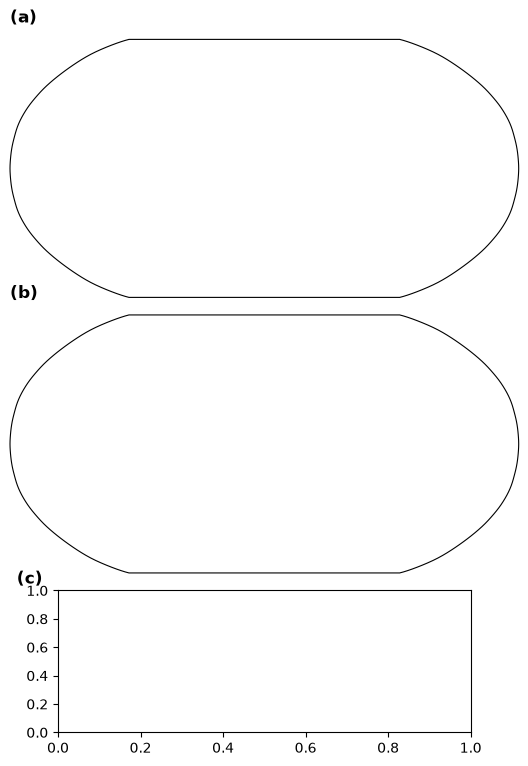

In [120]:
# Set up gridspec
month_order = config.months

fig = plt.figure(figsize=(7, 9))
gs = fig.add_gridspec(3, 1, height_ratios=[1, 1, 0.55], hspace=0.08)

ax_map1 = fig.add_subplot(gs[0], projection=ccrs.Robinson())
ax_map2 = fig.add_subplot(gs[1], projection=ccrs.Robinson())
gs_bot = gs[2].subgridspec(1, 3, width_ratios=[0.08, 1, 0.08])
ax = fig.add_subplot(gs_bot[1])

for label, a in zip(['(a)', '(b)'], [ax_map1, ax_map2]):
    a.text(0.0, 1.05, label, transform=a.transAxes,
           fontsize=12, fontweight='bold', va='bottom', ha='left')
for label, a in zip(['(c)'], [ax]):
    a.text(-0.1, 1.02, label, transform=a.transAxes,
           fontsize=12, fontweight='bold', va='bottom', ha='left')

In [121]:
anom = fc_land.mean(dim = ['month']) # 6-month avg anomaly
ens_mean = anom.mean("number") # ensemble mean

step = 0.5
vmax = np.ceil(float(abs(ens_mean).quantile(0.98)) / step) * step
levels = np.arange(-vmax, vmax + step, step)

mesh = ens_mean.plot.pcolormesh(
    ax=ax_map1, transform=ccrs.PlateCarree(),
    cmap="RdBu_r", levels=levels, extend="both",
    add_colorbar=False,
)

ax_map1.coastlines(linewidth=0.6, color="k")
ax_map1.set_global()

fig.colorbar(mesh, ax=ax_map1, orientation="horizontal", shrink=0.6, pad=0.05,
             label="Temperature anomaly (°C)")

plotting_utils.add_polygons(ax_map1, anom, threshold=0.9, transform=ccrs.PlateCarree())

<xarray.DataArray 'tas' (lat: 180, lon: 360)> Size: 518kB
dask.array<mean_agg-aggregate, shape=(180, 360), dtype=float64, chunksize=(90, 360), chunktype=numpy.ndarray>
Coordinates:
  * lat      (lat) float64 1kB 89.5 88.5 87.5 86.5 ... -86.5 -87.5 -88.5 -89.5
  * lon      (lon) float64 3kB -179.5 -178.5 -177.5 -176.5 ... 177.5 178.5 179.5
Attributes: (12/31)
    GRIB_dataType:                            fc
    GRIB_numberOfPoints:                      64800
    GRIB_typeOfLevel:                         surface
    GRIB_stepUnits:                           1
    GRIB_stepType:                            instant
    GRIB_gridType:                            regular_ll
    ...                                       ...
    units:                                    K
    standard_name:                            unknown
    GRIB_surface:                             0.0
    poreallas_created_at:                     2026-09-09T17:20:07.092312+00:00
    poreallas_uid:                            2958930b-7f7e-46db-9a7e-6e8d8cf...
    poreallas_description:                    Parsed ECMWF S51 ensemble tas f...

In [122]:
### Signal to Noise Ratio (Impact Region)
fc_ir = isku_utils.grid_to_ir(fc_anomaly.mean(dim = ['month']))
fc_6 = fc_ir     # 6-month mean anomaly per member
signal = fc_6.mean(dim="number")
noise = fc_6.std(dim="number")
snr = signal / noise
snr_df = analysis_utils.xarray_to_gpd(snr, config.polygons)

/home/emily_zuetell/projects/poreallas/utils/isku_utils.py:28: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  _region_weights = xr.load_dataset(uri)[
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/zarr/core/group.py:3413: ZarrUserWarning: Object at zarr.json:Zone.Identifier is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


In [123]:
gdf_plot = snr_df.to_crs(ax_map2.projection.proj4_init)

gdf_plot["value"] = gdf_plot["value"].abs()

vmax = np.nanquantile(gdf_plot["value"], 0.98)
cmap = "YlOrBr"
levels = [0, 0.25, 0.5, 0.75, 1, 1.5, 2, 3, 4, 5]
norm = mcolors.BoundaryNorm(levels, plt.get_cmap(cmap).N, extend="max")


gdf_plot.plot(column="value", ax=ax_map2, linewidth=0, cmap=cmap, norm=norm)

sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
fig.colorbar(sm, ax=ax_map2, orientation="horizontal", shrink=0.6, pad=0.03,
             extend="max", label="|Signal-to-noise ratio|")

ax_map2.coastlines(linewidth=0.6, color="k")
ax_map2.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())
#plotting_utils.add_region_polygons_vec(ax, ds_6, threshold=0.05, transform=ccrs.PlateCarree())
ax_map2.set_axis_off()


/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/shapely/constructive.py:829: RuntimeWarning: invalid value encountered in normalize
  return lib.normalize(geometry, **kwargs)


In [124]:
da = fc_land_mean
da = da.assign_coords(
    month=range(len(month_order))
)  # 0..5 positions instead of real month values

# Shaded 5-95 Interval
q = da.quantile([0.05, 0.95], dim='number')

ax.fill_between(
    da['month'],
    q.sel(quantile=0.05),
    q.sel(quantile=0.95),
    color='gray',
    alpha=0.3,
)

da.plot.line(x = 'month', color = 'gray', 
                    linewidth = 0.5, alpha = 0.5, 
                    ax=ax,
                    add_legend=False)
da.mean(dim = 'number').plot(marker="o", color = 'black', ax=ax)

ax.set_ylim(bottom=0)
ax.set_xticks(range(len(month_order)))
ax.set_xticklabels(month_order)
ax.set_xlabel("Month")
ax.set_ylabel("Land-Average \n Anomaly [C]")
ax.set_title("")

Text(0.5, 1.0, '')

In [125]:
# Spine Removal
ax.spines[['top', 'right']].set_visible(False)
ax_map1.spines['geo'].set_visible(False)
ax_map2.spines['geo'].set_visible(False)

ax.yaxis.set_major_locator(MultipleLocator(0.5))

ax.grid(axis='y', linestyle='--', linewidth=0.5, color='gray', alpha=0.4)
ax.set_axisbelow(True)

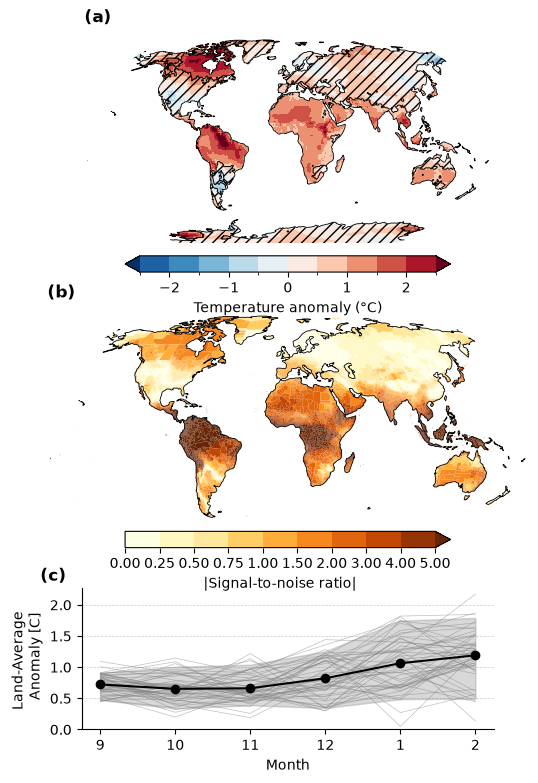

In [126]:
fig

In [127]:
fig.savefig("v261013_fig02_anomaly_CI.png", dpi=600, bbox_inches="tight")

# Figure 3. 
Aug-Jan cumulative net all-age mortality rate:

In [4]:
#effect_path = EFFECTS_URI
effect_path = "/home/emily_zuetell/projects/poreallas/data/v2609/v20260909_effects_with_betas.zarr"
effect = xr.open_datatree(effect_path)

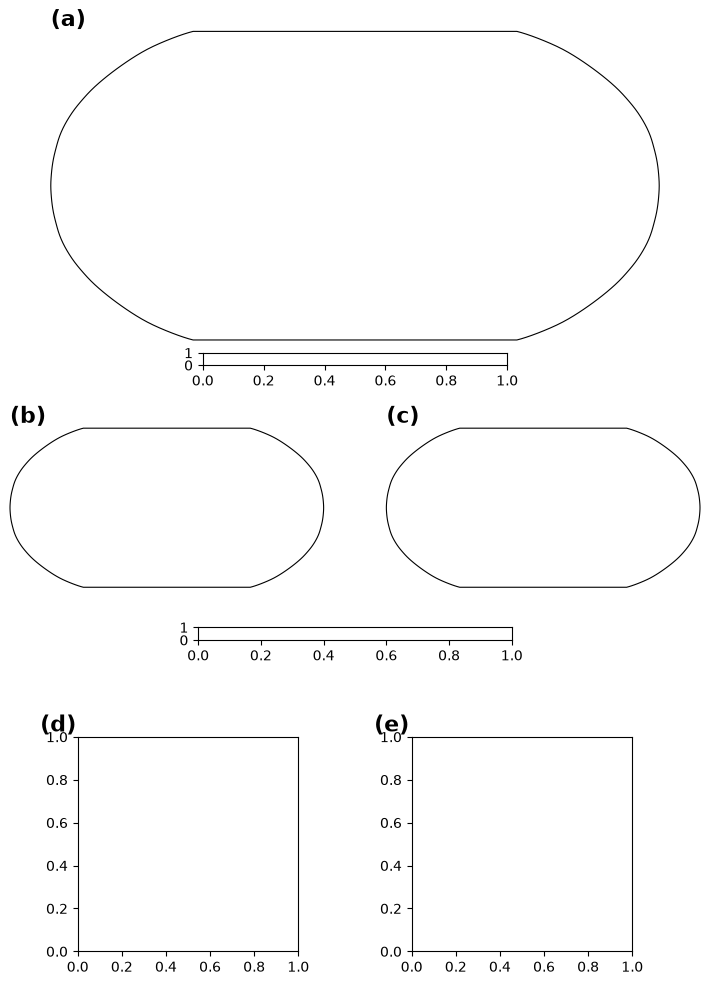

In [33]:
fig = plt.figure(figsize=(7.5, 10))
gs = fig.add_gridspec(4, 1, height_ratios=[1.4, 1, 0.1, 0.9], hspace=0.18,
                      left=0.05, right=0.97, top=0.97, bottom=0.05)

# Row 1: map (a) + its colorbar
gs_top = gs[0].subgridspec(2, 3, height_ratios=[1, 0.04], width_ratios=[1, 2, 1], hspace=0.08)
ax_a = fig.add_subplot(gs_top[0, :], projection=ccrs.Robinson())
cax_a = fig.add_subplot(gs_top[1, 1])

# Row 2: maps (b), (c) + shared colorbar
gs_mid = gs[1].subgridspec(2, 4, height_ratios=[1, 0.06], hspace=0.12, wspace=0.5)
ax_b = fig.add_subplot(gs_mid[0, :2], projection=ccrs.Robinson())
ax_c = fig.add_subplot(gs_mid[0, 2:], projection=ccrs.Robinson())
cax_bc = fig.add_subplot(gs_mid[1, 1:3])

# Row 3: timeseries (d), extra (e)
gs_bot = gs[3].subgridspec(1, 5, width_ratios=[0.1, 1, 0.1, 1, 0.1], wspace=0.45)
ax_timeseries = fig.add_subplot(gs_bot[1])
ax_extra = fig.add_subplot(gs_bot[3])

axes = [ax_a, ax_b, ax_c]
for ax, label in zip(axes, "abc"):
    ax.text(0.0, 1.0, f"({label})", transform=ax.transAxes,
            fontsize=16, fontweight="bold", ha="left", va="bottom")

for ax, label in zip([ax_timeseries, ax_extra], "de"):
    ax.text(-0.17, 1.0, f"({label})", transform=ax.transAxes,
            fontsize=16, fontweight="bold", ha="left", va="bottom")

In [34]:
# Compute the Mortality Impact relative to a Baseline Period for the Projected Effects
month_order = config.months
cmap = plt.get_cmap("coolwarm")
colors = {"net": 'gray', "hotonly": mcolors.to_hex(cmap(0.85)), "coldonly": mcolors.to_hex(cmap(0.15))}
ax = ax_timeseries
for hotonly in ["net", "hotonly", "coldonly"]:
    impact = analysis_utils.compute_impact(effect.chunk({dim: -1 for dim in config.dims}), 
                                           config,
                                           hotonly = hotonly,
                                           ensemble=True)
    ## Global Pop-Weighted ##
    da = impact.sel(month = config.months)
    pop = config.socioeconomics.pop.sel(region=da.region).fillna(0)
    da = da.weighted(pop).mean(dim='region')
    da = da.assign_coords(
        month=range(len(config.months))
    )  # 0..5 positions instead of real month values

    da.stack(sample_all=["number", "sample"]).reset_index("sample_all").plot.line(x='month', hue='sample_all', alpha=0.2, linewidth=.2, ax=ax, color=colors[hotonly])
    da.mean(dim=["number", "sample"]).plot(marker="o", ax=ax, label=hotonly, color=colors[hotonly])

    #da = impact.mean(dim = ['number', 'sample']).reindex(month=config.months)
    #da = da.assign_coords(
    #    month=range(len(config.months))
    #)  # 0..5 positions instead of real month values

    #pop = config.socioeconomics.pop.sel(region=da.region).fillna(0)

    # Random Subset
    #rng = np.random.default_rng(0)
    #idx = rng.choice(da.sizes['region'], size=da.sizes['region'] // 1000, replace=False)

    #da.isel(region=idx).plot.line(
    #    x='month', hue='region', alpha=0.4, linewidth=.2, ax=ax,
    #    color=colors[hotonly], add_legend=False)
    # pop-weighted mean
    #da.weighted(pop).mean(dim='region').plot(marker="o", ax=ax, label=hotonly, color=colors[hotonly])

ax.axhline(y=0, color="black", linewidth=0.5)
ax.set_xticks(range(len(month_order)))
ax.set_xticklabels(month_order)
ax.set_xlabel("Month")
ax.set_ylabel("6-month Mortality Rate \n[deaths/100k]")
names = {"net": "Net", "hotonly": "Hot Deaths", "coldonly": "Cold Deaths"}
handles, labels = ax.get_legend_handles_labels()
ax.legend(handles, [names.get(l, l) for l in labels], frameon=False)
ax.set_title("")

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_

Text(0.5, 1.0, '')

In [35]:
### Maps ###
# Compute fields
results = {}
for hotonly in ["net", "hotonly", "coldonly"]:
    impact = analysis_utils.compute_impact(effect.chunk({dim: -1 for dim in config.dims}), 
                                               config,
                                               ensemble=True,
                                               hotonly = hotonly)
    gdf = config.polygons.reset_index()
    gdf["geometry"] = gdf.geometry.make_valid()
    #select only 6-month forecast
    ds = impact.sel(month = config.months)

    geoms = gdf.set_index("region").loc[ds["region"].values, "geometry"]

    ds = (
        ds.assign_coords(geometry=("region", geoms.values))
        .swap_dims(region="geometry")
        .xvec.set_geom_indexes("geometry", crs=gdf.crs)
    )

    ds_6 = ds.sum(dim = ['month']) # 6-month total
    ens_mean = ds_6.mean(dim = ['sample', 'number']) # ensemble mean
    results[hotonly] = (ds_6, ens_mean)

def make_norm(means, step=5):
    all_abs = np.concatenate([abs(m).values.ravel() for m in means])
    vmax = np.ceil(np.nanquantile(all_abs, 0.98) / step) * step
    levels = np.round(np.arange(-vmax, vmax + step / 2, step), 10)
    cmap = plt.get_cmap("RdBu_r", len(levels) - 1 + 2)
    norm = mcolors.BoundaryNorm(levels, cmap.N, extend="both")
    return levels, cmap, norm

scale_a = make_norm([results["net"][1]])
scale_bc = make_norm([results["hotonly"][1], results["coldonly"][1]])

panels = [(ax_a, "net", scale_a), (ax_b, "hotonly", scale_bc), (ax_c, "coldonly", scale_bc)]

for ax, hotonly, (levels, cmap, norm) in panels:
    ds_6, ens_mean = results[hotonly]

    gdf_plot = ens_mean.xvec.to_geodataframe(name="anom").to_crs(ax.projection.proj4_init)
    gdf_plot.plot(column="anom", ax=ax, cmap=cmap, norm=norm, linewidth=0)

    ax.coastlines(linewidth=0.6, color="k")
    ax.set_extent([-180, 180, -60, 90], crs=ccrs.PlateCarree())
    ax.spines["geo"].set_visible(False)
    plotting_utils.add_region_polygons_vec(ax, ds_6, threshold=0.05, transform=ccrs.PlateCarree())
    ax.set_axis_off()

# Colorbars
for cax, (levels, cmap, norm) in [(cax_a, scale_a), (cax_bc, scale_bc)]:
    sm = plt.cm.ScalarMappable(norm=norm, cmap=cmap)
    cbar = fig.colorbar(sm, cax=cax, orientation="horizontal", extend="both",
                        label="Mortality Rate (deaths/100k)")
    cbar.set_ticks(levels[::2])

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_

In [36]:
def weighted_box_stats(vals, weights, whis=1.5):
    # weights = pop/pop_box
    mask = np.isfinite(vals) & np.isfinite(weights)
    v, w = vals[mask], weights[mask]
    order = np.argsort(v)
    v, w = v[order], w[order]
    # Normalize weights within box
    cdf = (np.cumsum(w) - 0.5 * w) / w.sum()
    q1, med, q3 = np.interp([0.25, 0.5, 0.75], cdf, v)
    iqr = q3 - q1
    whislo = v[v >= q1 - whis * iqr].min()
    whishi = v[v <= q3 + whis * iqr].max()
    return dict(med=med, q1=q1, q3=q3, whislo=whislo, whishi=whishi, fliers=[])

In [37]:
### Box Plot ###
quartile_labels = ["Low income", "Low-middle income", "Middle-high income", "High income"]
quartile_labels_display = [lbl.replace(" ", "\n", 1) for lbl in quartile_labels]

data_by_category = {}
for hotonly in ["net", "hotonly", "coldonly"]:
    impact = analysis_utils.compute_impact(effect.chunk({dim: -1 for dim in config.dims}), 
                                   config,
                                   ensemble=False,
                                   hotonly = hotonly)
    impact = impact.sel(month = config.months)
    #6-month total impact
    impact_mean = impact.sum(dim="month")
    if "number" in impact_mean.dims or "sample" in impact_mean.dims:
        impact_mean = impact_mean.mean(dim=[d for d in ["number", "sample"] if d in impact_mean.dims])

    impact_aligned, gdppc_aligned = xr.align(impact_mean, config.socioeconomics.gdppc, join="inner")
    region_vals = impact_aligned.values

    pop_aligned = config.socioeconomics.pop.sel(region=impact_aligned.region)

    sort_idx = np.argsort(gdppc_aligned.values)
    gdppc_sorted = gdppc_aligned.values[sort_idx]
    pop_sorted = pop_aligned.values[sort_idx]

    cum_pop = np.cumsum(pop_sorted)
    cum_pop_frac = cum_pop / cum_pop[-1]

    breakpoints = np.interp([0.25, 0.5, 0.75], cum_pop_frac, gdppc_sorted)
    bin_edges = np.concatenate([[gdppc_sorted[0] - 1], breakpoints, [gdppc_sorted[-1] + 1]])

    quartiles = pd.cut(gdppc_aligned.values, bins=bin_edges, labels=quartile_labels)
    pop_vals = pop_aligned.values
    data_by_category[hotonly] = [
        weighted_box_stats(region_vals[quartiles == q], pop_vals[quartiles == q])
        for q in quartile_labels
    ]

ax = ax_extra
positions = []
box_data = []
group_gap = 1
box_width = 0.6
n_quartiles = 4

for i, category in enumerate(["net", "hotonly", "coldonly"]):
    for j, q_data in enumerate(data_by_category[category]):
        positions.append(i * (n_quartiles + group_gap) + j)
        box_data.append(q_data)

bp = ax.bxp(
    box_data,
    positions=positions,
    widths=box_width,
    patch_artist=True,
    medianprops=dict(color="black"),
    showfliers=False,
)

for patch, color in zip(bp['boxes'], [colors[c] for c in ["net", "hotonly", "coldonly"] for _ in range(n_quartiles)]):
    patch.set_facecolor(color)

group_centers = [i * (n_quartiles + group_gap) + (n_quartiles - 1) / 2 for i in range(3)]

ax.set_ylim(-25, 25)
ax.set_xticks(positions)
ax.set_xticklabels(["L", "LM", "UM", "H"] * 3, fontsize=7, rotation=45)
ax.tick_params(axis="x", length=0)

ax.axhline(y=0, color="black", linewidth=0.5)
ax.set_ylabel("6-month Mortality Rate \n[deaths/100k]")

sec = ax.secondary_xaxis(-0.2)
sec.set_xticks(group_centers)
sec.set_xticklabels(["Net", "Hot", "Cold"])
sec.tick_params(length=0)

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


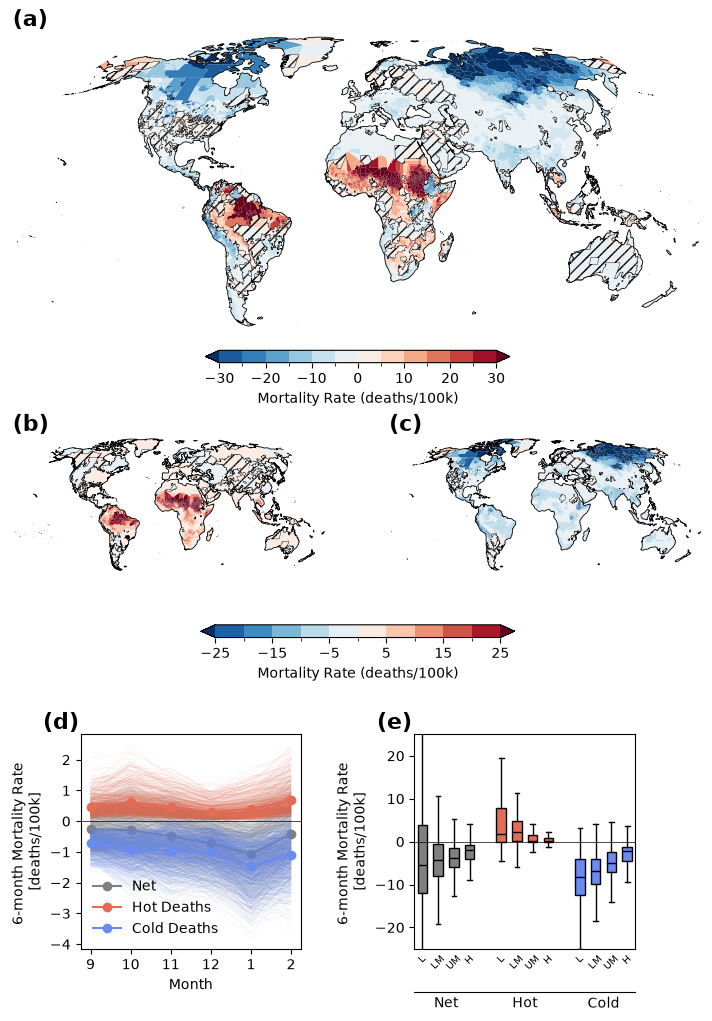

In [38]:
fig

In [39]:
fig.savefig("v261012_fig03_2609.png", dpi=600, bbox_inches="tight")

# Figure 5

In [ ]:
def plot_variance_decomposition(da, x_dim, factors=("sample", "number"),
                                labels=None, colors=None, figsize=(6.5, 5),
                                x_order=None):
    a, b = factors
    labels = labels or [a.capitalize(), b.capitalize(), "Interaction"]
    colors = colors or ["#0072B2", "#E69F00", "#6E706F"]  # Okabe-Ito, colorblind-safe
    # Month Order
    if x_order is not None:
        da = da.sel({x_dim: list(x_order)})

    # Two-way decomposition (ddof=0 makes it exact: total = var_a + var_b + var_ab)
    grand = da.mean((a, b))
    mean_a = da.mean(b)                      # varies along a
    mean_b = da.mean(a)                      # varies along b
    resid = da - mean_a - mean_b + grand
    # Decomposed Variance
    comps = [mean_a.var(a), mean_b.var(b), (resid ** 2).mean((a, b))]
    total = da.var((a, b))
    # Set x order
    x_vals = da[x_dim].values
    x = list(range(len(x_vals)))
    ys = [c.transpose(x_dim).values for c in comps]
    shares = [100 * y / total.values for y in ys]

    fig, (ax1, ax2) = plt.subplots(
        2, 1, sharex=True, figsize=figsize, constrained_layout=True,
        gridspec_kw={"height_ratios": [1.4, 1]},
    )
    # Raw Variance #
    ax1.stackplot(x, ys, labels=labels, colors=colors, alpha=0.9, linewidth=0)
    ax1.plot(x, total.values, color="k", lw=1.2, label="Total")
    ax1.set_ylabel("Variance")
    ax1.set_ylim(bottom=0)
    ax1.legend(ncol=4, frameon=False, loc="lower left",
               bbox_to_anchor=(0, 1.02), fontsize=9)
    ## Variance Share ##
    ax2.stackplot(x, shares, colors=colors, alpha=0.9, linewidth=0)
    ax2.set_ylim(0, 100)
    ax2.set_ylabel("Share of variance (%)")
    ax2.set_xlabel(x_dim)
    ax2.set_xlim(x[0], x[-1])
    ax2.set_xticks(x, [str(v) for v in x_vals])

    for ax, tag in zip((ax1, ax2), ("(a)", "(b)")):
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(direction="out", labelsize=9)
        ax.text(-0.1, 1.0, tag, transform=ax.transAxes,
                fontsize=11, fontweight="bold", va="top")

    return fig, (ax1, ax2)

In [33]:
config_f5 = analysis_utils.ImpactConfig( version = "v261005",
                                     baseline_period=BASELINE_PERIOD, 
                                     polygons_path= os.environ["POREALLAS_REGIONS_POLYGONS_URI"],
                                     socioeconomics_path= os.environ["POREALLAS_SOCIOECONOMICS_URI"],
                                     rate=True, 
                                     months = FC_MONTHS,
                                     hotonly = "hotonly", 
                                     dims = ['number', 'sample'])

In [34]:
effect_path = "/home/emily_zuetell/projects/poreallas/data/v261002_effects_hotonly_g100.zarr"
effect = xr.open_datatree(effect_path)
# Compute impact: forecast - baseline
impact = analysis_utils.compute_impact(
    effect.chunk({dim: -1 for dim in config.dims}),
    config_f5,
    ensemble=True,
)
# Use only the defined 6-months
impact = impact.sel(month=config.months).compute()

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_

In [ ]:
# Compute global impact (weighted sum)
global_impact = analysis_utils.compute_global_impact(
            impact, config.socioeconomics, rate=config.rate, group_dim='region'
        ).compute()

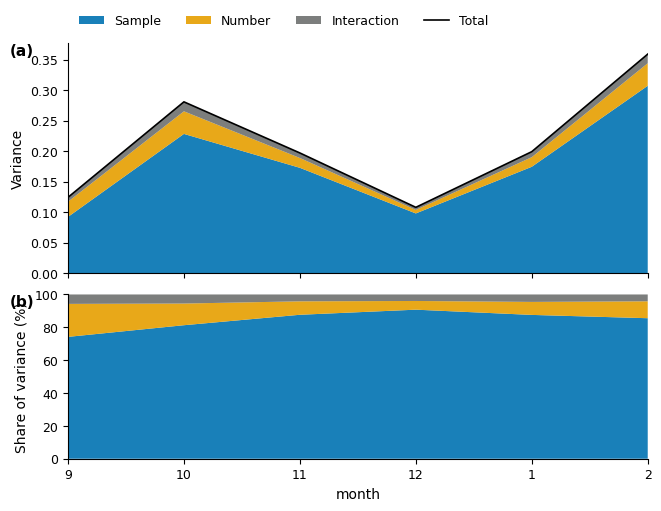

In [36]:
fig, axes = plot_variance_decomposition(global_impact, x_dim="month", x_order=config.months)

# Figure A3. 
Average forecast monthly temperature anomaly

In [ ]:
## Raw ##
# Raw Forecast/Hindcast
s51 = xr.open_zarr(TAS_FORECAST_RAW)
forecast = s51.sel(time=slice("2026-08-01", "2027-01-31")).groupby("time.month").mean()
hindcast = (
    s51.sel(time=config.baseline_period)
    .groupby("time.month")
    .mean()
    .sel(month=config.months)
)

In [ ]:
anomaly = forecast["tas"] - hindcast["tas"].mean(dim = 'number')
anomaly.name = "forecast_anomaly"

In [24]:
anomaly_ir = isku_utils.grid_to_ir(anomaly.compute(), savefile=None)
_polygons_anomaly = analysis_utils.xarray_to_gpd(
    anomaly_ir.mean(dim="number"), config.polygons
)

/home/emily_zuetell/projects/poreallas/analysis/isku_utils.py:29: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  _region_weights = xr.load_dataset(uri)[
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at zarr.json:Zone.Identifier is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


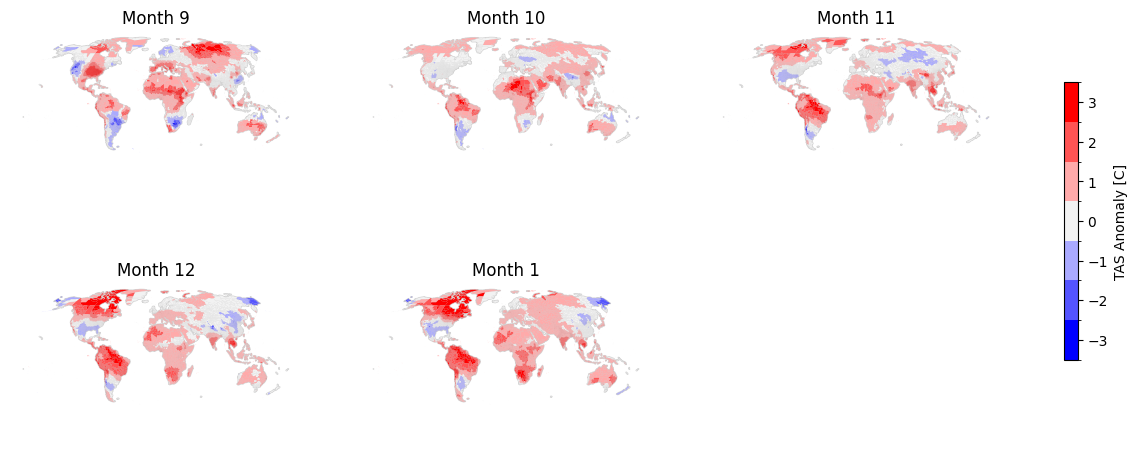

In [25]:
fig = plotting_utils.plot_monthly(
    _polygons_anomaly,
    col="value",
    cm="bwr",
    sup_title="",
    cbar_label="TAS Anomaly [C]",
    month_order=config.months,
)
fig.savefig("figA3raw_2608_anomaly.png", dpi=600, bbox_inches="tight")

In [26]:
## Corrected ##
era5 = xr.open_zarr(os.path.join(DATA_DIR, ERA5_URI)).sel(
    time=slice("1996-01-01", "2025-12-31")
)
forecast = xr.open_zarr(os.path.join(DATA_DIR, TAS_FORECAST_URI))

In [27]:
anomaly_corr = forecast.mean(dim=["number"]).groupby(
    "time.month"
).mean() - era5.groupby("time.month").mean().sel(month=config.months)

In [28]:
# Gridded to Impact Region
anomaly_corr_ir = isku_utils.grid_to_ir(anomaly_corr, savefile=None)
_polygons_anomaly_corr = analysis_utils.xarray_to_gpd(anomaly_corr_ir["tas"], config.polygons)

/home/emily_zuetell/projects/poreallas/analysis/isku_utils.py:29: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  _region_weights = xr.load_dataset(uri)[
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at zarr.json:Zone.Identifier is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


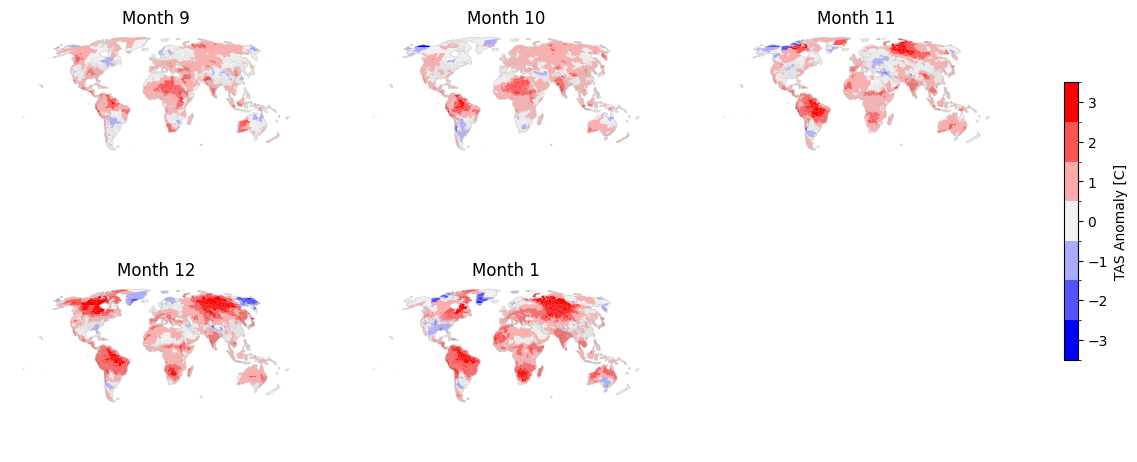

In [29]:
fig = plotting_utils.plot_monthly(
    _polygons_anomaly_corr,
    col="tas",
    cm="bwr",
    sup_title="",
    cbar_label="TAS Anomaly [C]",
    month_order=config.months,
)
fig.savefig("figA3era5_2608_anomaly.png", dpi=600, bbox_inches="tight")

# Figure A4. 
Forecast ensemble 10-90 percentile range in temperature by month:

In [30]:
forecast = s51.sel(time=slice("2026-08-01", "2027-01-31")).groupby("time.month").mean()
forecast_var = forecast["tas"].var(dim="number")

In [31]:
# Gridded to Impact Region
forecast_var_ir = isku_utils.grid_to_ir(forecast_var, savefile=None)
_polygons_forecast_var = analysis_utils.xarray_to_gpd(forecast_var_ir, config.polygons)

/home/emily_zuetell/projects/poreallas/analysis/isku_utils.py:29: RuntimeWarning: Failed to open Zarr store with consolidated metadata, but successfully read with non-consolidated metadata. This is typically much slower for opening a dataset. To silence this warning, consider:
1. Consolidating metadata in this existing store with zarr.consolidate_metadata().
2. Explicitly setting consolidated=False, to avoid trying to read consolidate metadata, or
3. Explicitly setting consolidated=True, to raise an error in this case instead of falling back to try reading non-consolidated metadata.
  _region_weights = xr.load_dataset(uri)[
/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/zarr/core/group.py:3289: ZarrUserWarning: Object at zarr.json:Zone.Identifier is not recognized as a component of a Zarr hierarchy.
  warnings.warn(


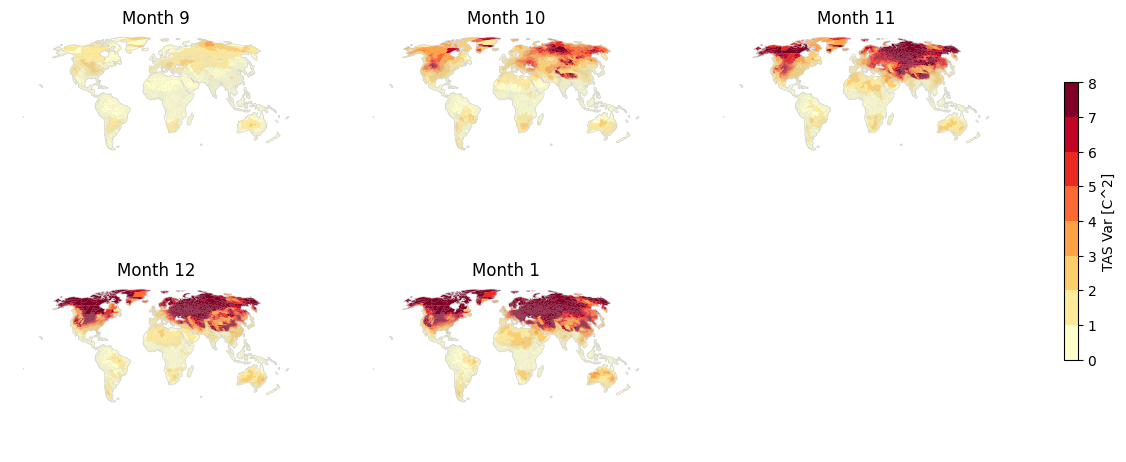

In [32]:
fig = plotting_utils.plot_monthly(
    _polygons_forecast_var,
    col="value",
    cm="YlOrRd",
    vmin=0,
    vmax=8,
    n_colors=10,
    sup_title="",
    cbar_label="TAS Var [C^2]",
    month_order=config.months,
)
fig.savefig("figA4_2608_forecast_var.png", dpi=600, bbox_inches="tight")

### Anomaly variance

In [33]:
_polygons_forecast_anomaly_var = analysis_utils.xarray_to_gpd(
    anomaly_ir.var(dim="number"), config.polygons
)

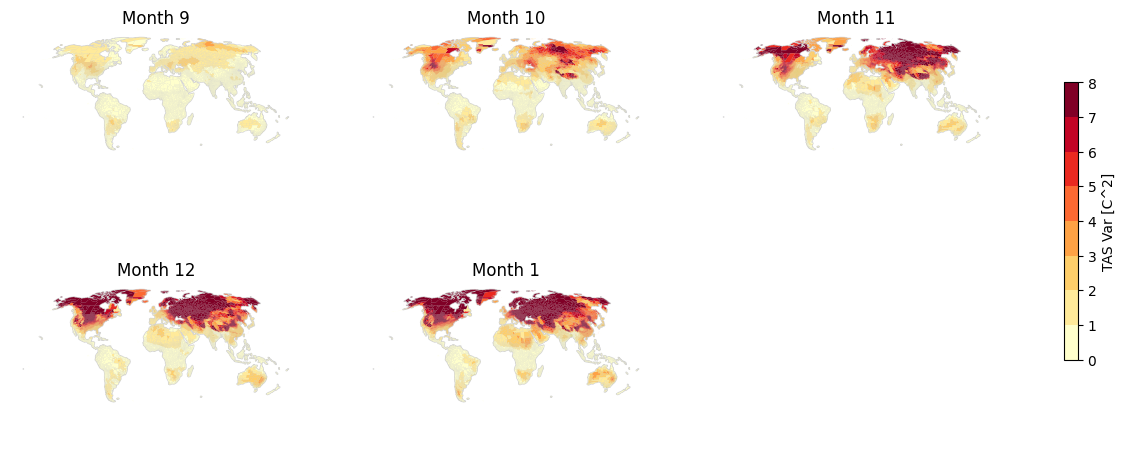

In [35]:
fig = plotting_utils.plot_monthly(
    _polygons_forecast_anomaly_var,
    col="value",
    cm="YlOrRd",
    vmin=0,
    vmax=8,
    n_colors=10,
    sup_title="",
    cbar_label="TAS Var [C^2]",
    month_order=config.months,
)
fig.savefig("figA4_2608_forecast_anom_var.png", dpi=600, bbox_inches="tight")

# Figure A6. 
Baseline age-weighted mean mortality rate by month: caption

# Figure A8. 
Change in age-weighted mean mortality rate by month: caption

In [38]:
impact = analysis_utils.compute_impact(effect.chunk({dim: -1 for dim in config.dims}), 
                                   config,
                                   ensemble=True,
                                   hotonly = "net")

In [39]:
_polygons_impact = analysis_utils.xarray_to_gpd(
    impact.mean(dim=["number", "sample"]), config.polygons
)

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


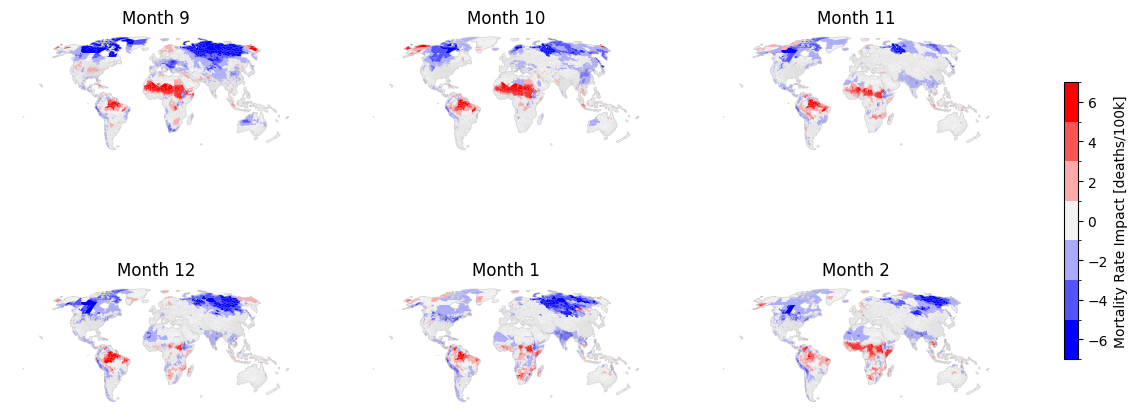

In [40]:
fig = plotting_utils.plot_monthly(
    _polygons_impact,
    col="age_weighted_impact",
    cm="bwr",
    sup_title="",
    cbar_label="Mortality Rate Impact [deaths/100k]",
    month_order=config.months,
)
fig.savefig("figA8_2608_monthly_rate_impact.png", dpi=600, bbox_inches="tight")

# Figure A9. 
Forecast uncertainty standard deviation of change in age-weighted mean mortality rate by month: caption

In [41]:
_polygons_impact_std = analysis_utils.xarray_to_gpd(
    impact.std(dim=["number", "sample"]), config.polygons
)

/home/emily_zuetell/projects/poreallas/.venv/lib/python3.14/site-packages/dask/_task_spec.py:768: RuntimeWarning: invalid value encountered in divide
  return self.func(*new_argspec)


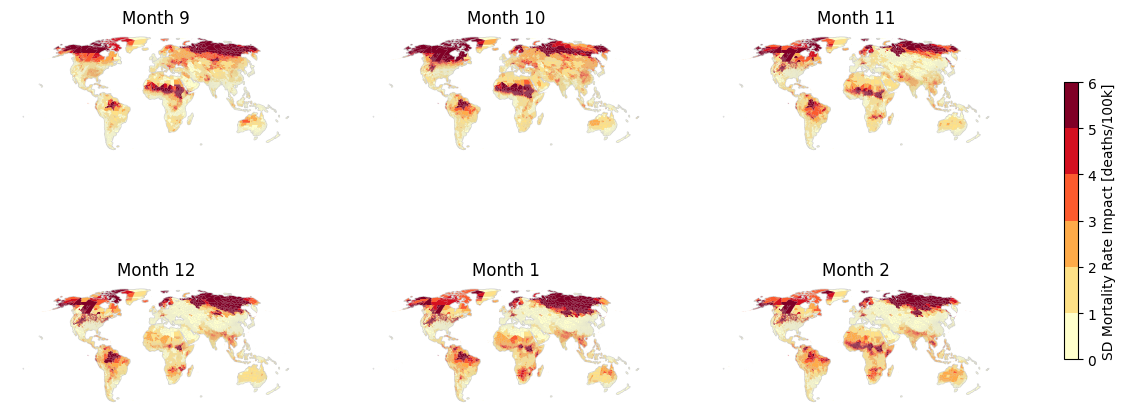

In [42]:
fig = plotting_utils.plot_monthly(
    _polygons_impact_std,
    col="age_weighted_impact",
    cm="YlOrRd",
    vmin=0,
    vmax=6,
    sup_title="",
    cbar_label="SD Mortality Rate Impact [deaths/100k]",
    month_order=config.months,
)
fig.savefig("figA9_2608_monthly_rate_impact_sd.png", dpi=600, bbox_inches="tight")